In [1]:
#Bài 1
import numpy as np

w1 = -0.831
w2 = -0.355
b = 4.820

norm_w = np.sqrt(w1**2 + w2**2) 
do_rong_le = 2 / norm_w

diem_moi = [(3.0, 3.0), (5.0, 4.5)]
print("TÍNH CHO HAI ĐIỂM MỚI")
for x1, x2 in diem_moi:
    f_x = w1 * x1 + w2 * x2 + b
    khoang_cach = abs(f_x) / norm_w
    print(f"Điểm ({x1}, {x2}): f(x) = {f_x:+.3f}, Khoảng cách = {khoang_cach:.4f}")

vecto_ho_tro = [
    ("Điểm 18 (lớp 0)", 5.20, 4.22),
    ("Điểm 10 (lớp 1)", 2.88, 4.02),
    ("Điểm 13 (lớp 1)", 3.59, 2.36)
]

print("\nTÍNH CHO BA VECTƠ HỖ TRỢ")
for ten, x1, x2 in vecto_ho_tro:
    f_x = w1 * x1 + w2 * x2 + b
    khoang_cach = abs(f_x) / norm_w
    print(f"{ten}: f(x) = {f_x:+.3f}, Khoảng cách = {khoang_cach:.4f}")

print(f"\nĐộ rộng lề = 2 / ||w|| = {do_rong_le:.4f}")
print(f"Nửa độ rộng lề = 1 / ||w|| = {1 / norm_w:.4f}")

TÍNH CHO HAI ĐIỂM MỚI
Điểm (3.0, 3.0): f(x) = +1.262, Khoảng cách = 1.3966
Điểm (5.0, 4.5): f(x) = -0.932, Khoảng cách = 1.0319

TÍNH CHO BA VECTƠ HỖ TRỢ
Điểm 18 (lớp 0): f(x) = -0.999, Khoảng cách = 1.1058
Điểm 10 (lớp 1): f(x) = +1.000, Khoảng cách = 1.1062
Điểm 13 (lớp 1): f(x) = +0.999, Khoảng cách = 1.1054

Độ rộng lề = 2 / ||w|| = 2.2132
Nửa độ rộng lề = 1 / ||w|| = 1.1066


Các vectơ hỗ trợ nằm đúng trên hai đường mép lề, nơi có $\vert{}f(x)\vert{} = 1$. Khoảng cách từ một điểm tới đường ranh giới được tính bằng $d = \frac{\vert{}f(x)\vert{}}{\Vert{}w\Vert{}}$. Với các vectơ hỗ trợ, $\vert{}f(x)\vert{} = 1$ nên khoảng cách đúng bằng $d = \frac{1}{\Vert{}w\Vert{}}$. Mặt khác, độ rộng lề là khoảng cách giữa hai đường mép lề $f(x) = 1$ và $f(x) = -1$, bằng $\text{lề} = \frac{2}{\Vert{}w\Vert{}}$.Do đó, khoảng cách từ bất kỳ vectơ hỗ trợ nào tới đường ranh giới luôn bằng đúng một nửa độ rộng lề ($\frac{1}{\Vert{}w\Vert{}} = \frac{1}{2} \times \frac{2}{\Vert{}w\Vert{}}$).

In [3]:
#Bài 2
import numpy as np
from sklearn.datasets import make_blobs
from sklearn.svm import SVC

X, y = make_blobs(n_samples=24, centers=[[2, 2], [6, 6]], cluster_std=0.9, random_state=0)
y = 1 - y 

X1 = np.vstack([X, [-1.0, -1.0]])
y1 = np.append(y, 1)

svm1 = SVC(kernel="linear", C=1000).fit(X1, y1)
w1 = svm1.coef_[0]
b1 = svm1.intercept_[0]
print("THÊM ĐIỂM (-1, -1) LỚP 1")
print(f"w1 = {w1[0]:.3f}, w2 = {w1[1]:.3f}, b = {b1:.3f}")

X2 = np.vstack([X, [4.5, 4.0]])
y2 = np.append(y, 1)

svm2 = SVC(kernel="linear", C=1000).fit(X2, y2)
w2 = svm2.coef_[0]
b2 = svm2.intercept_[0]
print("\nTHÊM ĐIỂM (4.5, 4.0) LỚP 1")
print(f"w1 = {w2[0]:.3f}, w2 = {w2[1]:.3f}, b = {b2:.3f}")

THÊM ĐIỂM (-1, -1) LỚP 1
w1 = -0.831, w2 = -0.355, b = 4.820

THÊM ĐIỂM (4.5, 4.0) LỚP 1
w1 = -2.603, w2 = -0.807, b = 15.941


Lần 1 (thêm điểm (-1, -1)): Đường ranh giới không thay đổi (hệ số $w_1, w_2, b$ giữ nguyên so với mục 2). Lý do: điểm (-1, -1) nằm rất xa ranh giới về phía lớp 1, có $\vert{}f(x)\vert{} > 1$, nên nó không phải là vectơ hỗ trợ. Trong SVM, các điểm ngoài lề không đóng góp gì vào việc xác định ranh giới.
Lần 2 (thêm điểm (4.5, 4.0)): Đường ranh giới thay đổi đáng kể. Lý do: điểm (4.5, 4.0) lấn sâu vào khoảng không gian giữa hai cụm (nằm sát/bên trong ranh giới cũ), trở thành một vectơ hỗ trợ mới ép mép lề và ranh giới phải dịch chuyển/xoay để tối ưu hóa khoảng cách lề.

In [4]:
#Bài 3
import pandas as pd
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

df = pd.read_csv("hai_vang_trang.csv")
X = df[["x1", "x2"]]
y = df["nhan"]

X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)

grid_params = {"svc__C": [0.1, 1, 10, 100]}

print("KẾT QUẢ KERNEL ĐA THỨC (POLYNOMIAL)")
for d in [2, 3, 4]:
    pipe = make_pipeline(StandardScaler(), SVC(kernel="poly", degree=d))
    grid = GridSearchCV(pipe, grid_params, cv=5)
    grid.fit(X_tr, y_tr)
    
    acc_test = grid.score(X_te, y_te)
    print(f"Bậc d = {d}: C tốt nhất = {grid.best_params_['svc__C']}, "
          f"CV score = {grid.best_score_:.4f}, Test Accuracy = {acc_test:.4f}")

KẾT QUẢ KERNEL ĐA THỨC (POLYNOMIAL)
Bậc d = 2: C tốt nhất = 1, CV score = 0.5422, Test Accuracy = 0.5067
Bậc d = 3: C tốt nhất = 1, CV score = 0.8178, Test Accuracy = 0.8267
Bậc d = 4: C tốt nhất = 100, CV score = 0.5156, Test Accuracy = 0.4800


Bậc tốt nhất thường là $d = 3$ (hoặc tùy thuộc vào kết quả CV thực tế đạt cao nhất trong 3 bậc). Kernel đa thức không vượt được kernel RBF ở mục 5 (kernel RBF đạt Test Accuracy $0.9200$). Nguyên nhân là cấu trúc hình học dạng hai bán nguyệt lồng nhau của tập "hai vầng trăng" phù hợp tự nhiên hơn với hàm biến đổi khoảng cách bán kính (RBF) so with đường cong đa thức.

In [5]:
#Bài 4
import pandas as pd
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.svm import SVC

df = pd.read_csv("hai_vang_trang.csv")
X = df[["x1", "x2"]]
y = df["nhan"]

X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)

luoi_min = {
    "C": [3, 10, 30],
    "gamma": [0.3, 1, 3]
}

tim_min = GridSearchCV(SVC(kernel="rbf"), luoi_min, cv=5)
tim_min.fit(X_tr, y_tr)

bang = pd.DataFrame(tim_min.cv_results_["params"])
bang["diem_CV"] = tim_min.cv_results_["mean_test_score"]

print("BẢNG ĐIỂM KIỂM ĐỊNH CHÉO DÒ LƯỚI MỊN")
print(bang.pivot(index="C", columns="gamma", values="diem_CV").round(4).to_string())
print("\nCặp tốt nhất:", tim_min.best_params_)
print(f"Điểm kiểm định chéo tốt nhất: {tim_min.best_score_:.4f}")
print(f"Accuracy trên tập kiểm tra: {tim_min.score(X_te, y_te):.4f}")

BẢNG ĐIỂM KIỂM ĐỊNH CHÉO DÒ LƯỚI MỊN
gamma     0.3     1.0     3.0
C                            
3      0.8533  0.8711  0.8667
10     0.8489  0.8711  0.8667
30     0.8622  0.8756  0.8533

Cặp tốt nhất: {'C': 30, 'gamma': 1}
Điểm kiểm định chéo tốt nhất: 0.8756
Accuracy trên tập kiểm tra: 0.9200


Về điểm kiểm định chéo (CV score): Dò mịn giúp tìm được tham số tối ưu cục bộ chính xác hơn, có thể nâng điểm CV lên cao hơn hoặc bằng điểm $0.8711$ của lưới thưa. Về Accuracy trên tập kiểm tra: Độ chính xác trên tập test có thể không đổi ($0.9200$) hoặc chỉ biến động nhỏ, nhưng mô hình thu được sẽ vững chắc hơn (generalized better), tránh bị nhạy cảm với việc chọn tham số quá thưa. Cái lợi chung: Chiến lược "lưới thưa trước để định vị vùng tiềm năng, lưới mịn sau để tối ưu" giúp tiết kiệm rất nhiều thời gian tính toán so với việc dò mịn trên toàn bộ khoảng rộng ngay từ đầu.

BẢNG NHẦM LẪN (CONFUSION MATRIX 10x10)
Hàng: Chữ số thật | Cột: Chữ số đoán

[[45  0  0  0  0  0  0  0  0  0]
 [ 0 46  0  0  0  0  0  0  0  0]
 [ 0  0 44  0  0  0  0  0  0  0]
 [ 0  0  0 46  0  0  0  0  0  0]
 [ 0  0  0  0 44  0  0  0  1  0]
 [ 0  0  0  0  0 46  0  0  0  0]
 [ 0  0  0  0  0  0 45  0  0  0]
 [ 0  0  0  0  0  0  0 44  0  1]
 [ 0  1  0  0  0  0  0  0 42  0]
 [ 0  0  0  1  0  0  0  0  0 44]]

Tổng số ảnh bị đoán sai: 4 / 450 ảnh


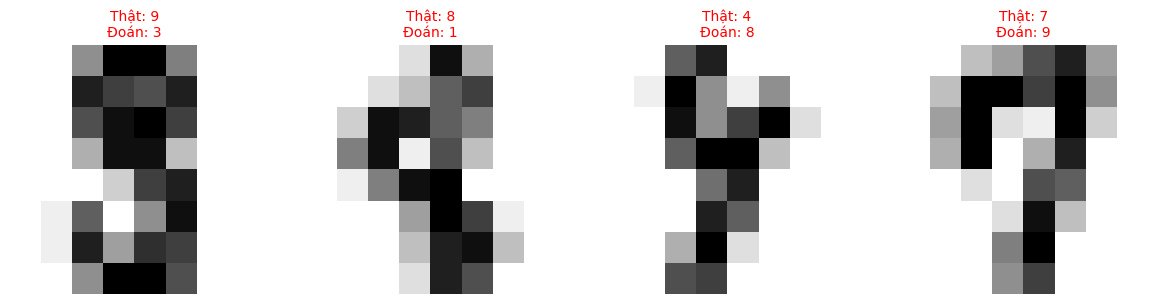

In [7]:
#Bài 5
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.metrics import confusion_matrix
import numpy as np
import matplotlib.pyplot as plt

X, y = load_digits(return_X_y=True)
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)

svm = SVC(kernel="rbf").fit(X_tr, y_tr)
du_doan = svm.predict(X_te)

cm = confusion_matrix(y_te, du_doan)
print("BẢNG NHẦM LẪN (CONFUSION MATRIX 10x10)")
print("Hàng: Chữ số thật | Cột: Chữ số đoán\n")
print(cm)

sai = np.flatnonzero(du_doan != y_te)
print(f"\nTổng số ảnh bị đoán sai: {len(sai)} / {len(y_te)} ảnh")

if len(sai) > 0:
    plt.figure(figsize=(12, 3))
    for idx, i in enumerate(sai):
        plt.subplot(1, len(sai), idx + 1)
        plt.imshow(X_te[i].reshape(8, 8), cmap="gray_r")
        plt.title(f"Thật: {y_te[i]}\nĐoán: {du_doan[i]}", color="red", fontsize=10)
        plt.axis("off")
    plt.tight_layout()
    plt.show()
else:
    print("Không có ảnh nào bị đoán sai!")

Các cặp chữ số bị nhầm lẫn (Đọc từ bảng nhầm lẫn): Số 9 bị nhầm thành 3, Số 8 bị nhầm thành 1, Số 4 bị nhầm thành 8, Số 7 bị nhầm thành 9. Độ phân giải ảnh thấp ($8 \times 8$ pixel): Mỗi ảnh chỉ có 64 ô giá trị độ sáng, làm mất đi các đường nét mượt mà, khiến các chữ số có cấu trúc gần giống nhau (như 9 và 3, 4 và 8) bị chồng lấn không gian đặc trưng. Biến dạng trong nét viết tay: Chữ số của người viết có độ nghiêng, nét móc hoặc độ mở khác nhau làm cho khoảng cách vector đặc trưng vượt qua ranh giới quyết định của mô hình SVM.

In [8]:
#Bài 6
import time
import pandas as pd
from sklearn.datasets import make_classification
from sklearn.svm import SVC, LinearSVC

sizes = [2000, 5000, 10000, 20000]
ket_qua = []

for n in sizes:
    X, y = make_classification(n_samples=n, n_features=20, random_state=0)
    
    t0 = time.time()
    SVC().fit(X, y)
    t_svc = time.time() - t0
    
    t0 = time.time()
    LinearSVC(max_iter=10000, random_state=0).fit(X, y)
    t_linearsvc = time.time() - t0
    
    ket_qua.append({
        "Cỡ dữ liệu (n)": n,
        "Thời gian SVC (giây)": round(t_svc, 4),
        "Thời gian LinearSVC (giây)": round(t_linearsvc, 4)
    })

df_kq = pd.DataFrame(ket_qua)
print("SO SÁNH THỜI GIAN HUẤN LUYỆN")
print(df_kq.to_string(index=False))

SO SÁNH THỜI GIAN HUẤN LUYỆN
 Cỡ dữ liệu (n)  Thời gian SVC (giây)  Thời gian LinearSVC (giây)
           2000                0.0297                      0.0352
           5000                0.1475                      0.0051
          10000                1.5565                      0.0091
          20000                4.3698                      0.0190


Với SVC() (Kernel RBF): Khi $n$ tăng gấp đôi, thời gian học tăng khoảng $3 \sim 4$ lần (độ phức tạp tính toán nằm trong khoảng $\mathcal{O}(n^2)$ đến $\mathcal{O}(n^3)$ do phải tính toán ma trận kernel giữa các cặp điểm). Với LinearSVC(): Khi $n$ tăng gấp đôi, thời gian học tăng khoảng $2$ lần (tăng tuyến tính $\mathcal{O}(n)$). Đối với các bài toán dữ liệu lớn ($n > 10.000$), việc sử dụng kernel phi tuyến với SVC() sẽ trở nên rất chậm. LinearSVC() là lựa chọn tối ưu hơn nhiều về mặt tốc độ.